In [1]:
%pylab inline
import gc
import fitsio
import treecorr
import numpy as np
import catutil

Populating the interactive namespace from numpy and matplotlib


# Cosmic shear measurement on mocks

## merge 6 observational fields

In [2]:
nzs    =   4
def read_mock_catalog(fname='mock_nres13_r003_rotmat12_shear_catalog.fits',mbias=0.):
    '''
    Load mock catalog and divide into 4 redshift bins.
    Parameters:
    ---
    fname: file name of the mock catalog from Shirasaki-San
    mbias: The multiplicative bias (including estimation bias and selection bias) [float]
    
    Returns:
    data:   S19A mock catalog (with m=mbias) [ndarray]
    '''
    # here I use the dnnz since the mock is based on dnnz
    pzname  =   'dnnz' #demp/mizuki/dnnz
    pzDir   =   'wrkDir/catalog/'
    # 4 bins
    dataG  =   [[],[],[],[]]
    for fieldname in catutil.field_names:
        # mock catalog (will copy v2 to GW and idark)
        catFname=  'wrkDir/g3Sim/catalog_mock/shape/%s/%s' %(fieldname,fname)
        data   =   fitsio.read(catFname)
        data   =   make_mock_catalog(data,mbias)
        # avoid infinite |e|
        mask0  =   (data['e1_mock']**2.+data['e2_mock']**2.)<10.
        # selection using measured photo-z (not the true source photo-z)
        pzsname=   os.path.join(pzDir,'%s_%s_zmask.fits' %(fieldname,pzname))
        for iz in range(nzs):
            zmsk   =   fitsio.read(pzsname)['%s_mask_%sbin' %(pzname,iz)]&mask0
            # merge observational fields
            dataG[iz].append(data[zmsk])
        del data,zmsk
        gc.collect()
    dataG=[np.hstack(dataG[i]) for i in range(nzs)]
    print('number of galaxies in each bin:',len(dataG[0]),len(dataG[1]),len(dataG[2]),len(dataG[3]))
    return dataG

def make_mock_catalog(data0,mbias):
    '''
    Rescale the shear by multiplicative bias and derive the 
    mock ellipticities.
    Parameters:
    ---
    data0:  HSC S19A mock catalog (assuming m=0) [ndarray]
    mbias: The multiplicative bias (including estimation bias and selection bias) [float]
    Returns:
    data:   Updated S19A mock catalog (with m=mbias) [ndarray]
    '''
    data=data0.copy()
    # Calcualte the distortions and rescaled by (1+m)
    gamma_sq=(data['shear1_sim']**2.+data['shear2_sim']**2.)*(1+mbias)**2.
    dis1=2.*(1-data['kappa'])*data['shear1_sim']*(1+mbias)/\
        ((1-data['kappa'])**2+gamma_sq)\
        
    dis2=2.*(1-data['kappa'])*data['shear2_sim']/\
        ((1-data['kappa'])**2+gamma_sq)\
        *(1+mbias)
    # Calculate the mock ellitpicities
    dd=dis1**2+dis2**2.
    de=dis1*data['noise1_int']+dis2*data['noise2_int']
    #nominator e1
    e1_mock=data['noise1_int']+dis1+dis2/dd*(1-(1-dd)**0.5)*(dis1*data['noise2_int']-dis2*data['noise1_int'])
    data['e1_mock']=e1_mock/(1+de)+data['noise1_mea']
    #nominator e2
    e2_mock=data['noise2_int']+dis2+dis1/dd*(1-(1-dd)**0.5)*(dis2*data['noise1_int']-dis1*data['noise2_int'])
    data['e2_mock']=e2_mock/(1+de)+data['noise2_mea']
    return data

In [3]:
%%time
dataG=read_mock_catalog(mbias=-0.1) #testing the spped

/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:61: RuntimeWarning: invalid value encountered in true_divide
/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:64: RuntimeWarning: invalid value encountered in true_divide
/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/ipykernel_launcher.py:24: RuntimeWarning: invalid value encountered in less


number of galaxies in each bin: 1765482 8601117 9477599 7379172
CPU times: user 11 s, sys: 46.9 s, total: 57.9 s
Wall time: 59 s


## Measuring correlations

In [4]:
def measure_cs(dataG,mbias=0.):
    cor  =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
    out={}
    for ii in range(nzs):
        resI1=1.-np.sum(dataG[ii]['weight']*dataG[ii]['noise1_int']**2.)/np.sum(dataG[ii]['weight'])
        # |resI1-resI2|~1e-4; hence just use resI1
        #resI2=1.-np.sum(dataG[ii]['weight']*dataG[ii]['noise2_int']**2.)/np.sum(dataG[ii]['weight'])
        #print(resI1,resI2)
        g1I=dataG[ii]['e1_mock']/2./resI1/(1+mbias)
        g2I=dataG[ii]['e2_mock']/2./resI1/(1+mbias)
        catEi  =   treecorr.Catalog(g1=g1I,g2=-g2I,\
                                    ra=dataG[ii]['ra_mock'],dec=dataG[ii]['dec_mock'],\
                                    w=dataG[ii]['weight'],ra_units='deg',dec_units='deg') 
        for jj in range(ii,nzs):
            resJ1=1.-np.sum(dataG[jj]['weight']*dataG[jj]['noise1_int']**2.)/np.sum(dataG[jj]['weight'])
            g1J=dataG[jj]['e1_mock']/2./resJ1
            g2J=dataG[jj]['e2_mock']/2./resJ1
            catEj  =   treecorr.Catalog(g1=g1J,g2=-g2J,\
                                        ra=dataG[jj]['ra_mock'],dec=dataG[jj]['dec_mock'],\
                                        w=dataG[jj]['weight'],ra_units='deg',dec_units='deg') 
            # correlation 
            cor.clear()
            cor.process(catEi,catEj)
            del catEj
            gc.collect()
            out.update({'%d%d'%(ii,jj):cor.copy()})
    return out

In [5]:
%%time
cors0=measure_cs(dataG) # test speed

CPU times: user 53min 33s, sys: 30.5 s, total: 54min 4s
Wall time: 3min 31s


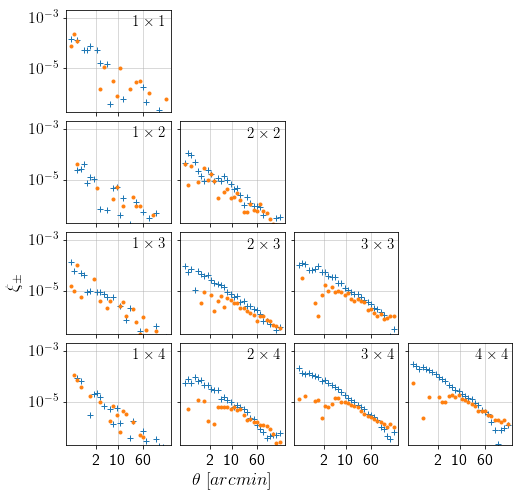

In [6]:
def plot_cosmicShear(cors):
    # make plot
    plt.close()
    fig = plt.figure(figsize=(8,8))
    for i in range(nzs):
        for j in range(i,nzs):
            ax = plt.subplot2grid((8, 8), (j*2, i*2), colspan=2,rowspan=2)
            ax.set_ylim(2e-7,2e-3)
            ax.set_title(r'$%d \times %d$' %(i+1,j+1),fontsize=15,y=1.0, pad=-15,x=0.8)
            ax.set_xscale('log')
            ax.set_yscale('log')
            ax.grid()
            if i!=0:
                #ax.get_yaxis().set_visible(False)
                ax.set_yticklabels(('',''))
                #ax.set_yticklabels(('$10^{-5}$','$10^{-4}$'))
            if j!=nzs-1:
                #ax.get_xaxis().set_visible(False)
                ax.set_xticks((2,10,60))
                ax.set_xticklabels(('','',''))
            else:
                ax.set_xticks((2,10,60))
                ax.set_xticklabels(('2','10','60'))
            if i==0 and j==2:
                ax.set_ylabel(r'$\xi_{\pm}$')
            if j==nzs-1 and i==1:
                ax.set_xlabel(r'$\theta~[arcmin]$')
            ax.plot(cors['%d%d'%(i,j)].rnom,cors['%d%d'%(i,j)].xip,'+')
            ax.plot(cors['%d%d'%(i,j)].rnom,cors['%d%d'%(i,j)].xim,'.')
    return
plot_cosmicShear(cors0)

## Check whether the result is consistent with correlating g

In [7]:
def measure_cs_g(dataG):
    cor  =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
    out={}
    for ii in range(nzs):
        g1I=dataG[ii]['shear1_sim']
        g2I=dataG[ii]['shear2_sim']
        catEi  =   treecorr.Catalog(g1=g1I,g2=-g2I,\
                                    ra=dataG[ii]['ra_mock'],dec=dataG[ii]['dec_mock'],\
                                    w=dataG[ii]['weight'],ra_units='deg',dec_units='deg') 
        for jj in range(ii,nzs):
            g1J=dataG[jj]['shear1_sim']
            g2J=dataG[jj]['shear2_sim']
            catEj  =   treecorr.Catalog(g1=g1J,g2=-g2J,\
                                        ra=dataG[jj]['ra_mock'],dec=dataG[jj]['dec_mock'],\
                                        w=dataG[jj]['weight'],ra_units='deg',dec_units='deg') 
            # correlation 
            cor.clear()
            cor.process(catEi,catEj)
            del catEj
            gc.collect()
            out.update({'%d%d'%(ii,jj):cor.copy()})
    return out

In [ ]:
%%time
cors1=measure_cs_g(dataG)

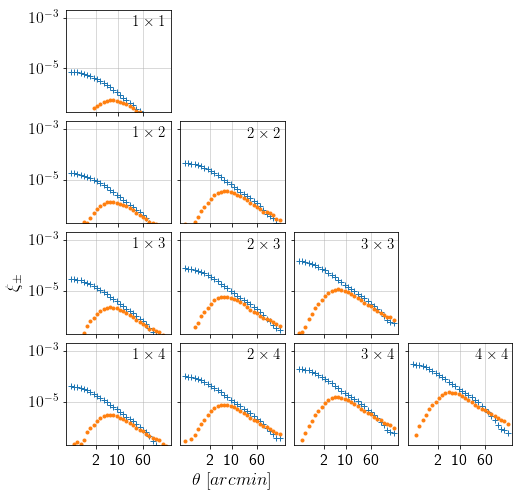

In [9]:
plot_cosmicShear(cors1)

In [ ]:
import glob

fieldname='XMM'
Dir='wrkDir/g3Sim/catalog_mock/shape_v2/'
fnames=glob.glob(os.path.join(Dir,fieldname,'*.fits'))[0:200]

g1All=np.zeros(len(fnames))
for ii,catFname in enumerate(fnames):
    g1All[ii]=np.average(fitsio.read(catFname)['shear1_sim'])
    gc.collect()